Configurações e Funções Auxiliares

In [1]:
import textwrap
from pathlib import Path


import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd()

ARQUIVO_BRUTO = ROOT / "dados_originais" / "datatran2025.csv"
ARQUIVO_TRATADO = ROOT / "base_tratada.csv"
FIG_DIR = ROOT / "figuras"
DOCS_DIR = ROOT / "docs"
for pasta in (ARQUIVO_TRATADO.parent, FIG_DIR, DOCS_DIR):
    pasta.mkdir(parents=True, exist_ok=True)

SEED = 2026
FONTE = "Fonte: PRF, Dados Abertos - BAT 2025 (agrupado por ocorrência)"


pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def fmt(n):
    """padrão brasileiro"""
    return f"{int(n):,}".replace(",", ".")


def salvar(fig, nome):
    fig.text(0.01, 0.005, FONTE, fontsize=7, color="gray", ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=150)
    plt.show()


def ler_dadoBruto(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"O Arquivo '{path.name}' não foi encontrado em {path.parent.name}")
    
    for enc in ("latin-1", "utf-8", "iso-8859-1"):
        try:
            return pd.read_csv(path, sep=";", encoding=enc, low_memory=False), path.name
        except UnicodeDecodeError:
            continue
            
    raise ValueError(f"Não foi possível decodificar o arquivo em '{path}'.")

Categorização e Preparação dos Dados

In [2]:
dadoBruto, nome_csv = ler_dadoBruto(ARQUIVO_BRUTO)
dadoBruto.columns = dadoBruto.columns.str.strip().str.lower()
N_BRUTO = len(dadoBruto)

print(f"Arquivo CSV lido: {nome_csv}")
print(f"Registros antes do tratamento: {fmt(N_BRUTO)}")
print(f"Colunas ({dadoBruto.shape[1]}): {list(dadoBruto.columns)}")
dadoBruto.head()

Arquivo CSV lido: datatran2025.csv
Registros antes do tratamento: 72.529
Colunas (30): ['id', 'data_inversa', 'dia_semana', 'horario', 'uf', 'br', 'km', 'municipio', 'causa_acidente', 'tipo_acidente', 'classificacao_acidente', 'fase_dia', 'sentido_via', 'condicao_metereologica', 'tipo_pista', 'tracado_via', 'uso_solo', 'pessoas', 'mortos', 'feridos_leves', 'feridos_graves', 'ilesos', 'ignorados', 'feridos', 'veiculos', 'latitude', 'longitude', 'regional', 'delegacia', 'uop']


,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,classificacao_acidente,fase_dia,sentido_via,condicao_metereologica,tipo_pista,tracado_via,uso_solo,pessoas,mortos,feridos_leves,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,652493,2025-01-01,quarta-feira,06:20:00,SP,116,225,GUARULHOS,Reação tardia ou ineficiente do condutor,Tombamento,Com Vítimas Feridas,Pleno dia,Decrescente,Céu Claro,Múltipla,Reta;Declive,Sim,2,0,1,0,0,1,1,2,"-23,48586772","-46,54075317",SPRF-SP,DEL01-SP,UOP01-DEL01-SP
1,652519,2025-01-01,quarta-feira,07:50:00,CE,116,"546,2",PENAFORTE,Pista esburacada,Colisão frontal,NaN,Pleno dia,Crescente,Céu Claro,Simples,Reta,Não,6,1,1,0,1,4,1,6,"-7,812288","-39,08333306",SPRF-CE,DEL05-CE,UOP03-DEL05-CE
2,652522,2025-01-01,quarta-feira,08:45:00,PR,369,"88,2",CORNELIO PROCOPIO,Reação tardia ou ineficiente do condutor,Colisão traseira,Com Vítimas Feridas,Pleno dia,Crescente,Sol,Dupla,Reta;Aclive,Sim,5,0,3,0,2,0,3,2,"-23,182565","-50,637228",SPRF-PR,DEL07-PR,UOP05-DEL07-PR
3,652544,2025-01-01,quarta-feira,11:00:00,PR,116,74,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Saída de leito carroçável,Com Vítimas Feridas,Pleno dia,Crescente,Céu Claro,Dupla,Reta,Não,5,0,1,0,4,0,1,2,"-25,36517687","-49,04223028",SPRF-PR,DEL01-PR,UOP02-DEL01-PR
4,652549,2025-01-01,quarta-feira,09:30:00,MG,251,471,FRANCISCO SA,Velocidade Incompatível,Colisão frontal,Com Vítimas Feridas,Pleno dia,Decrescente,Chuva,Simples,Curva;Declive,Não,5,0,1,1,1,2,2,4,"-16,46801304","-43,43121303",SPRF-MG,DEL12-MG,UOP01-DEL12-MG


In [3]:
# Contrato de dados 
COLUNAS_ESSENCIAIS = ["id", "data_inversa", "tipo_acidente", "pessoas", "mortos", "veiculos"]
ausentes = [c for c in COLUNAS_ESSENCIAIS if c not in dadoBruto.columns]

assert not ausentes, f"Colunas ausentes: {ausentes}. Disponíveis: {list(dadoBruto.columns)}"

log = [] # registro de decisão de tratamento 

def registrar(etapa, antes, depois, obs=""):
    log.append({
        "etapa": etapa,
        "registros_antes": antes,
        "registros_depois": depois,
        "removidos": antes - depois,
        "observação": obs
    })

df = dadoBruto.copy()

# Tratamento de texto
for c in ["tipo_acidente", "classificacao_acidente", "causa_acidente", "fase_dia", "uf"]:
    if c in df.columns:
        df[c] = df[c].astype("string").str.strip()

NUM = [c for c in ["pessoas", "mortos", "feridos_leves", "feridos_graves", "ilesos", "ignorados", "feridos", "veiculos"] if c in df.columns]

# Tratamento de números
nao_numericos = {}
for c in NUM:
    antes_na = df[c].isna().sum()
    df[c] = pd.to_numeric(df[c], errors="coerce")
    nao_numericos[c] = int(df[c].isna().sum() - antes_na)

print("Valores não numéricos convertidos em ausente:", {k: v for k, v in nao_numericos.items() if v} or "nenhum")

# Tratamento de datas (formatos)
d = pd.to_datetime(df["data_inversa"], errors="coerce", format="%Y-%m-%d")
sem_data = d.isna() & df["data_inversa"].notna()
d[sem_data] = pd.to_datetime(df.loc[sem_data, "data_inversa"], errors="coerce", format="%d/%m/%Y")
df["data"] = d
print("Período na base:", df["data"].min().date(), "a", df["data"].max().date())


registrar("Leitura da base original", len(dadoBruto), len(df), "sem exclusões")

# Valores ausentes
chaves = ["id", "data", "tipo_acidente", "pessoas", "mortos", "veiculos"]
aus = df.isna().sum().to_frame("ausentes")
aus["% do total"] = (aus["ausentes"] / len(df) * 100).round(3)
print("-- Valores Ausentes --")
print("Ausentes nas variáveis-chave: ")
display(aus.loc[chaves])

# Remoção por linhas apenas nas colunas essenciais para cálculo 
antes = len(df)
df = df.dropna(subset=chaves)
registrar("Remoção de ausentes nas variáveis-chave", antes, len(df), f"colunas: {chaves}")

# Filtro do período das ocorrências de 2025
antes = len(df)
df = df[df["data"].dt.year == 2025].copy()
registrar("Filtro: ocorrências em 2025", antes, len(df), "mantém apenas datas entre 2025-01-01 e 2025-12-31")

# Duplicidades
n_linha_duplicada = int(df.duplicated().sum())
n_id_duplicada = int(df["id"].duplicated().sum())
print(f"Linhas idênticas: {n_linha_duplicada} | IDs repetidos: {n_id_duplicada}")

""""Remoção de linhas totalmente idênticas"""
antes = len(df)
df = df.drop_duplicates()
registrar("Remoção de linhas idênticas", antes, len(df), "mantida a primeira ocorrência")

"""Remoção de IDs duplicados"""
antes = len(df)
df = df.drop_duplicates(subset="id", keep="first")
registrar("Remoção de IDs repetidos", antes, len(df), "mantida a primeira ocorrência do ID")

# Valores Inconsistentes 
cats = [c for c in ["mortos", "feridos_leves", "feridos_graves", "ilesos", "ignorados"] if c in df.columns]

testes = {
    "valores negativos (pessoas, mortos ou veiculos)": (df[["pessoas", "mortos", "veiculos"]] < 0).any(axis=1),
    "mais mortos do que pessoas": df["mortos"] > df["pessoas"],
    "nenhuma pessoa envolvida (pessoas == 0)": df["pessoas"] == 0,
    "nenhum veículo envolvido (veiculos == 0)": df["veiculos"] == 0
}

EXCLUIR = list(testes.keys())

quadro = pd.DataFrame({"registros": {k: int(v.sum()) for k, v in testes.items()}})
quadro["ação"] = ["excluir" if k in EXCLUIR else "manter" for k in quadro.index]

print("\n-- Inconsistências --")
display(quadro)

invalido = np.logical_or.reduce([testes[k] for k in EXCLUIR])
antes = len(df)
df = df[~invalido].copy()
registrar("Remoção de registros logicamente inválidos", antes, len(df), f"regras: {'; '.join(EXCLUIR)}")

# Verificação de valores extremos 
print("\n-- Verificação de extremos --")
for v in ["pessoas", "veiculos", "mortos"]:
    q1, q3 = df[v].quantile([.25, .75])
    lim = q3 + 1.5 * (q3 - q1)
    print(f"{v}: máx = {int(df[v].max())} | acima de Q3+1,5·IQR ({lim:.1f}): {fmt((df[v] > lim).sum())} registros")

print("\nOs 10 acidentes com mais pessoas envolvidas:")
colunas_ver = [c for c in ["id", "data", "uf", "tipo_acidente", "pessoas", "mortos", "veiculos"] if c in df.columns]
display(df.nlargest(10, "pessoas")[colunas_ver])
print("Os 10 acidentes com mais veículos:")
display(df.nlargest(10, "veiculos")[colunas_ver])

Valores não numéricos convertidos em ausente: nenhum
Período na base: 2025-01-01 a 2025-12-31
-- Valores Ausentes --
Ausentes nas variáveis-chave: 


,ausentes,% do total
id,0,0.0
data,0,0.0
tipo_acidente,0,0.0
pessoas,0,0.0
mortos,0,0.0
veiculos,0,0.0


Linhas idênticas: 0 | IDs repetidos: 0

-- Inconsistências --


,registros,ação
"valores negativos (pessoas, mortos ou veiculos)",0,excluir
mais mortos do que pessoas,0,excluir
nenhuma pessoa envolvida (pessoas == 0),0,excluir
nenhum veículo envolvido (veiculos == 0),0,excluir



-- Verificação de extremos --
pessoas: máx = 76 | acima de Q3+1,5·IQR (4.5): 6.360 registros
veiculos: máx = 82 | acima de Q3+1,5·IQR (3.5): 5.219 registros
mortos: máx = 16 | acima de Q3+1,5·IQR (0.0): 5.210 registros

Os 10 acidentes com mais pessoas envolvidas:


,id,data,uf,tipo_acidente,pessoas,mortos,veiculos
54082,716289,2025-09-05,MG,Colisão traseira,76,4,2
16694,734818,2025-11-28,MG,Colisão traseira,73,0,4
32614,673084,2025-04-12,SP,Incêndio,71,0,1
1633,659998,2025-02-08,SP,Saída de leito carroçável,69,0,3
10867,710458,2025-08-08,MT,Colisão frontal,69,11,5
11155,711782,2025-07-16,GO,Colisão frontal,69,5,4
70684,740829,2025-12-22,PE,Colisão traseira,65,0,2
20464,654624,2025-01-12,MG,Engavetamento,63,0,5
47483,706383,2025-07-22,MG,Colisão frontal,62,0,3
37734,691808,2025-05-17,GO,Colisão transversal,60,2,2


Os 10 acidentes com mais veículos:


,id,data,uf,tipo_acidente,pessoas,mortos,veiculos
10260,707992,2025-07-07,GO,Incêndio,2,0,82
18547,748976,2025-04-06,SC,Colisão com objeto,33,0,31
9474,704931,2025-07-15,ES,Colisão frontal,11,1,21
4193,670979,2025-04-01,MT,Colisão lateral mesmo sentido,8,1,18
62630,729013,2025-11-01,PI,Colisão traseira,19,0,18
11831,714599,2025-07-15,SC,Engavetamento,15,0,17
5492,687933,2025-04-28,PR,Engavetamento,11,1,16
4945,685337,2025-04-12,MT,Incêndio,2,0,15
7738,697678,2025-06-12,AL,Engavetamento,17,1,15
7469,696512,2025-05-14,PR,Colisão transversal,3,0,14


In [4]:
# Identificação de acidente com vítima fatal 
df["com_vitima_fatal"] = (df["mortos"] >= 1).astype(int)  # 1 = acidente com pelo menos 1 morte
for c in [c for c in NUM if c in df.columns]:
    df[c] = df[c].astype(int)

COLS_SAIDA = [c for c in ["id", "data", "uf", "br", "tipo_acidente", "classificacao_acidente", "causa_acidente", "fase_dia", "pessoas", "mortos", "feridos_leves", "feridos_graves", "ilesos", "ignorados", "veiculos", "com_vitima_fatal"] if c in df.columns]
tratado = df[COLS_SAIDA].reset_index(drop=True)

# Verificação de tamanho mínimo da amostra final (>1.000)
N_FINAL = len(tratado)
assert N_FINAL >= 1000, "Falha: A base tratada ficou com menos de 1.000 registros"

# Exportação dos arquivos finais
tratado.to_csv(ARQUIVO_TRATADO, index=False, encoding="utf-8-sig")
LOG_PATH = DOCS_DIR / "tratamento_log.csv"
pd.DataFrame(log).to_csv(LOG_PATH, index=False, encoding="utf-8-sig")

# Resumo da execução
n_bruto_total = len(dadoBruto)
print(f"Registros antes do tratamento: {fmt(n_bruto_total)}")
print(f"Registros depois do tratamento: {fmt(N_FINAL)} ({((n_bruto_total - N_FINAL) / n_bruto_total * 100):.2f}% removidos)")

# Tabela de log
display(pd.DataFrame(log))

# Dicionário de dados da base final
dicionario = pd.DataFrame([
    ("id", "Identificador do acidente", "Qualitativa nominal (identificador)", "-"),
    ("data", "Data da ocorrência", "Temporal", "dia (AAAA-MM-DD)"),
    ("uf", "Unidade da Federação onde ocorreu o acidente", "Qualitativa nominal", "sigla"),
    ("br", "Rodovia federal (BR) do acidente", "Qualitativa nominal", "número da BR"),
    ("tipo_acidente", "Tipo do acidente (ex.: colisão frontal, tombamento)", "Qualitativa nominal", "categoria"),
    ("classificacao_acidente", "Gravidade registrada (sem vítimas, feridos, fatais)", "Qualitativa ordinal", "categoria"),
    ("causa_acidente", "Causa do acidente registrada pela PRF", "Qualitativa nominal", "categoria"),
    ("fase_dia", "Fase do dia (amanhecer, pleno dia, anoitecer, plena noite)", "Qualitativa nominal", "categoria"),
    ("pessoas", "Total de pessoas envolvidas no acidente", "Quantitativa discreta", "pessoas"),
    ("mortos", "Pessoas que morreram no acidente", "Quantitativa discreta", "pessoas"),
    ("feridos_leves", "Pessoas com ferimentos leves", "Quantitativa discreta", "pessoas"),
    ("feridos_graves", "Pessoas com ferimentos graves", "Quantitativa discreta", "pessoas"),
    ("ilesos", "Pessoas sem ferimentos", "Quantitativa discreta", "pessoas"),
    ("ignorados", "Pessoas com estado ignorado", "Quantitativa discreta", "pessoas"),
    ("veiculos", "Quantidade de veículos envolvidos", "Quantitativa discreta", "veículos"),
    ("com_vitima_fatal", "CRIADA: 1 se mortos ≥ 1, 0 caso contrário", "Qualitativa nominal (binária)", "0/1"),
], columns=["variável", "significado", "classificação", "unidade"])

# Exibe o dicionário apenas com as colunas presentes na saída
display(dicionario[dicionario["variável"].isin(COLS_SAIDA)].reset_index(drop=True))

Registros antes do tratamento: 72.529
Registros depois do tratamento: 72.529 (0.00% removidos)


,etapa,registros_antes,registros_depois,removidos,observação
0,Leitura da base original,72529,72529,0,sem exclusões
1,Remoção de ausentes nas variáveis-chave,72529,72529,0,"colunas: ['id', 'data', 'tipo_acidente', 'pess..."
2,Filtro: ocorrências em 2025,72529,72529,0,mantém apenas datas entre 2025-01-01 e 2025-12-31
3,Remoção de linhas idênticas,72529,72529,0,mantida a primeira ocorrência
4,Remoção de IDs repetidos,72529,72529,0,mantida a primeira ocorrência do ID
5,Remoção de registros logicamente inválidos,72529,72529,0,"regras: valores negativos (pessoas, mortos ou ..."


,variável,significado,classificação,unidade
0,id,Identificador do acidente,Qualitativa nominal (identificador),-
1,data,Data da ocorrência,Temporal,dia (AAAA-MM-DD)
2,uf,Unidade da Federação onde ocorreu o acidente,Qualitativa nominal,sigla
3,br,Rodovia federal (BR) do acidente,Qualitativa nominal,número da BR
4,tipo_acidente,"Tipo do acidente (ex.: colisão frontal, tombam...",Qualitativa nominal,categoria
5,classificacao_acidente,"Gravidade registrada (sem vítimas, feridos, fa...",Qualitativa ordinal,categoria
6,causa_acidente,Causa do acidente registrada pela PRF,Qualitativa nominal,categoria
7,fase_dia,"Fase do dia (amanhecer, pleno dia, anoitecer, ...",Qualitativa nominal,categoria
8,pessoas,Total de pessoas envolvidas no acidente,Quantitativa discreta,pessoas
9,mortos,Pessoas que morreram no acidente,Quantitativa discreta,pessoas


Estatística Descritiva

In [5]:
df = pd.read_csv(ARQUIVO_TRATADO, parse_dates=["data"])
print(f"Base tratada carregada: {fmt(len(df))} registros, {df.shape[1]} colunas\n")

def resumo(s, ddof=1):
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({
        "n": s.size, "média": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
        "mínimo": s.min(), "máximo": s.max(), "amplitude": s.max() - s.min(),
        "Q1": q1, "Q3": q3, "P90": s.quantile(.90), "P95": s.quantile(.95), "P99": s.quantile(.99),
        "variância": s.var(ddof=ddof), "desvio-padrão": s.std(ddof=ddof), "assimetria": s.skew(),
    })

VARIAVEIS_QUANTITATIVAS = ["mortos", "pessoas", "veiculos"]
tab = pd.DataFrame({v: resumo(df[v]) for v in VARIAVEIS_QUANTITATIVAS})
display(tab.round(3))

# Coeficiente de variação
for v in VARIAVEIS_QUANTITATIVAS:
    m, s = df[v].mean(), df[v].std(ddof=1)
    if m >= 1:
        print(f"Coeficiente de Variação de {v}: {s / m * 100:.1f}%")
    else:
        print(f"Coeficiente de Variação de {v}: não calculado (média = {m:.3f}, muito próxima de zero e variável concentrada em 0; "f"a razão desvio/média ficaria instável e pouco interpretável).")

Base tratada carregada: 72.529 registros, 16 colunas



,mortos,pessoas,veiculos
n,72529.000,72529.000,72529.000
média,0.083,2.597,1.998
mediana,0.000,2.000,2.000
moda,0.000,2.000,2.000
mínimo,0.000,1.000,1.000
máximo,16.000,76.000,82.000
amplitude,16.000,75.000,81.000
Q1,0.000,2.000,1.000
Q3,0.000,3.000,2.000
P90,0.000,4.000,3.000


Coeficiente de Variação de mortos: não calculado (média = 0.083, muito próxima de zero e variável concentrada em 0; a razão desvio/média ficaria instável e pouco interpretável).
Coeficiente de Variação de pessoas: 86.8%
Coeficiente de Variação de veiculos: 56.4%


,frequência absoluta,frequência relativa (%),acumulada (%)
tipo de acidente,,,
Colisão traseira,14360,19.80,19.80
Saída de leito carroçável,10209,14.08,33.87
Colisão transversal,9306,12.83,46.71
Colisão lateral mesmo sentido,7885,10.87,57.58
Tombamento,6351,8.76,66.33
Colisão com objeto,5109,7.04,73.38
Colisão frontal,4739,6.53,79.91
Queda de ocupante de veículo,3450,4.76,84.67
Atropelamento de Pedestre,3057,4.21,88.88


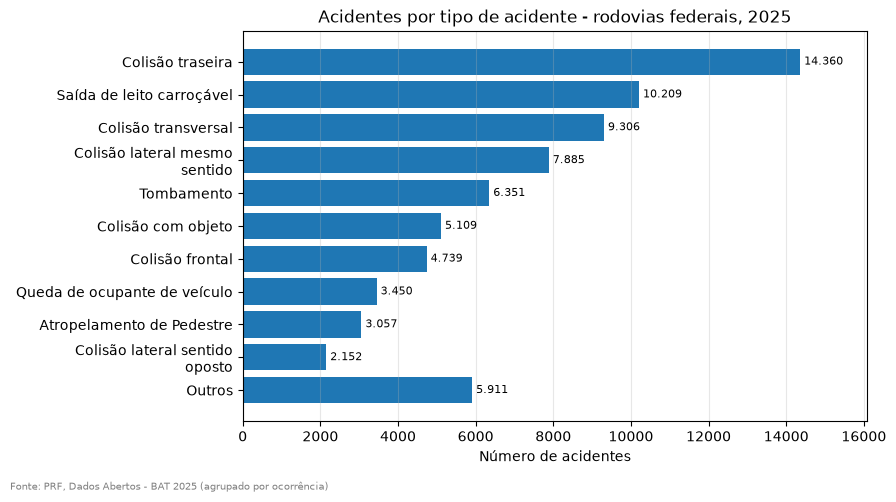

In [6]:
# Tabela de frequências e gráfico de barras: tipo de acidente
freq = df["tipo_acidente"].value_counts()
tab_freq = pd.DataFrame({
    "frequência absoluta": freq,
    "frequência relativa (%)": (freq / freq.sum() * 100).round(2),
    "acumulada (%)": (freq / freq.sum() * 100).cumsum().round(2),
})
tab_freq.index.name = "tipo de acidente"
display(tab_freq)

TOP = 10
graf = freq.head(TOP).copy()
if len(freq) > TOP:
    graf["Outros"] = freq.iloc[TOP:].sum()
fig, ax = plt.subplots(figsize=(9, 5))
rotulos = [textwrap.fill(str(t), 28) for t in graf.index][::-1]
valores = graf.values[::-1]
ax.barh(rotulos, valores)
for i, v in enumerate(valores):
    ax.text(v, i, f" {fmt(v)}", va="center", fontsize=8)
ax.set_xlabel("Número de acidentes")
ax.set_title("Acidentes por tipo de acidente - rodovias federais, 2025")
ax.margins(x=0.12)
ax.grid(axis="y", visible=False)
salvar(fig, "barras_tipo_acidente")

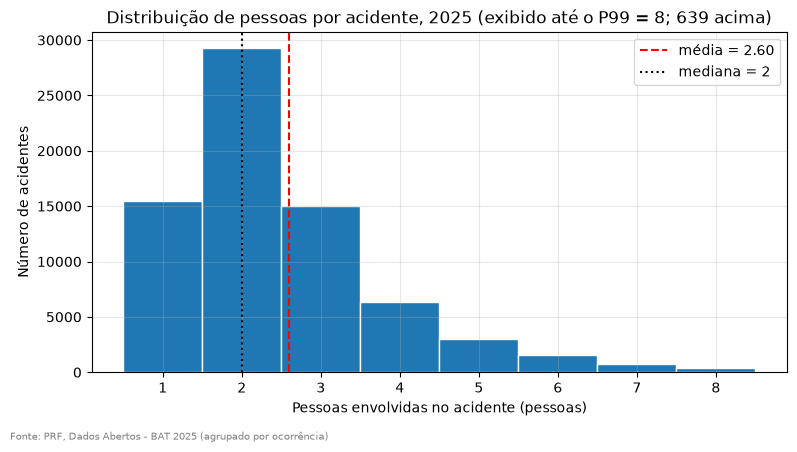

In [7]:
# Histograma: pessoas envolvidas por acidente
lim = int(df["pessoas"].quantile(.99))
acima = int((df["pessoas"] > lim).sum())
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df.loc[df["pessoas"] <= lim, "pessoas"], bins=np.arange(0.5, lim + 1.5, 1), edgecolor="white")
ax.axvline(df["pessoas"].mean(), color="red", ls="--", label=f"média = {df['pessoas'].mean():.2f}")
ax.axvline(df["pessoas"].median(), color="black", ls=":", label=f"mediana = {df['pessoas'].median():.0f}")
ax.set_xlabel("Pessoas envolvidas no acidente (pessoas)")
ax.set_ylabel("Número de acidentes")
ax.set_title(f"Distribuição de pessoas por acidente, 2025 (exibido até o P99 = {lim}; {fmt(acima)} acima)")
ax.legend()
salvar(fig, "histograma_pessoas")

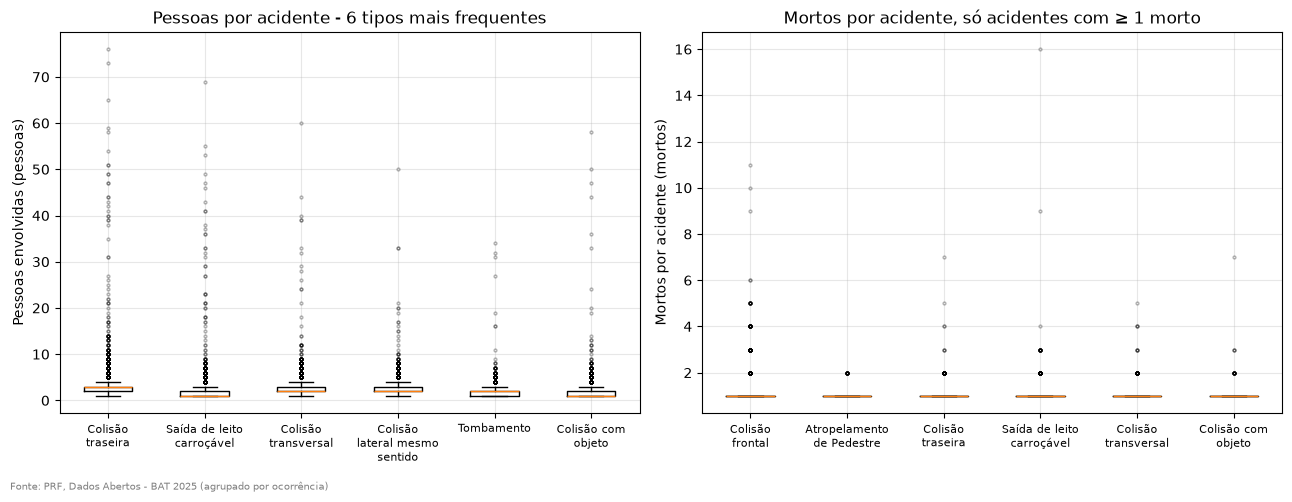

In [8]:
# Boxplots: Comparação de grupos (tipos de acidente)
topo_tipos = freq.head(6).index.tolist()
dados1 = [df.loc[df["tipo_acidente"] == t, "pessoas"] for t in topo_tipos]

fatais = df[df["mortos"] >= 1]
topo_fatais = fatais["tipo_acidente"].value_counts().head(6).index.tolist()
dados2 = [fatais.loc[fatais["tipo_acidente"] == t, "mortos"] for t in topo_fatais]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.boxplot(dados1, flierprops=dict(markersize=2, alpha=0.3))
ax1.set_xticks(range(1, len(topo_tipos) + 1))
ax1.set_xticklabels([textwrap.fill(t, 14) for t in topo_tipos], fontsize=8)
ax1.set_ylabel("Pessoas envolvidas (pessoas)")
ax1.set_title("Pessoas por acidente - 6 tipos mais frequentes")

ax2.boxplot(dados2, flierprops=dict(markersize=2, alpha=0.3))
ax2.set_xticks(range(1, len(topo_fatais) + 1))
ax2.set_xticklabels([textwrap.fill(t, 14) for t in topo_fatais], fontsize=8)
ax2.set_ylabel("Mortos por acidente (mortos)")
ax2.set_title("Mortos por acidente, só acidentes com ≥ 1 morto")
salvar(fig, "boxplot_tipo_acidente")

-- Pergunta 1: Gravidade fatal por tipo de acidente --
Como a quantidade de vítimas fatais varia entre os diferentes tipos de acidentes registrados nas rodovias federais durante o ano de 2025?


,acidentes,total_mortos,media_mortos,max_mortos,pct_com_morte,mortos_por_100_acidentes
tipo de acidente,,,,,,
Colisão frontal,4739,1863,0.39,11,29.46,39.31
Atropelamento de Pedestre,3057,919,0.30,2,29.51,30.06
Colisão lateral sentido oposto,2152,255,0.12,6,9.85,11.85
Eventos atípicos,287,24,0.08,2,8.01,8.36
Saída de leito carroçável,10209,700,0.07,16,5.93,6.86
Atropelamento de Animal,1133,74,0.07,2,6.00,6.53
Colisão com objeto,5109,323,0.06,7,5.81,6.32
Capotamento,1373,74,0.05,3,4.59,5.39
Colisão transversal,9306,481,0.05,5,4.59,5.17


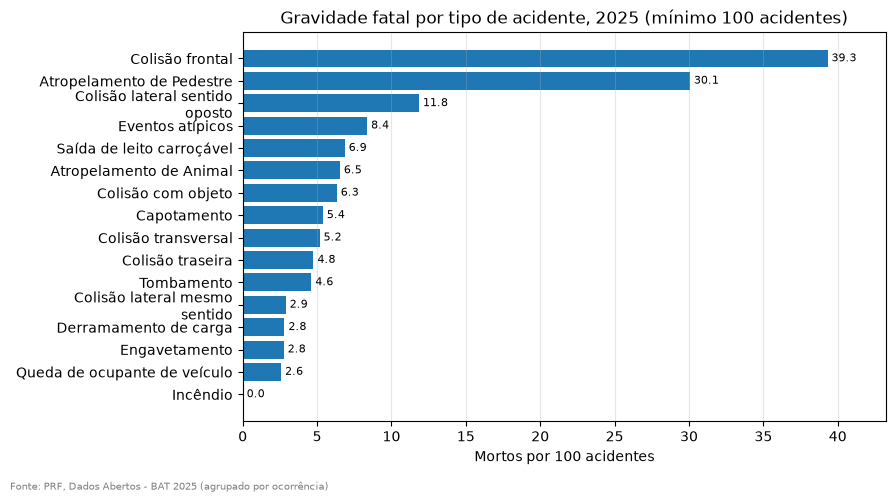

In [9]:
# Pergunta 1: Variação de Vítimas Fatais entre os Tipos de Acidente

MIN_ACIDENTES = 100  # filtro que ignora taxas instáveis

por_tipo = df.groupby("tipo_acidente").agg(
    acidentes=("id", "size"),
    total_mortos=("mortos", "sum"),
    media_mortos=("mortos", "mean"),
    max_mortos=("mortos", "max"),
    pct_com_morte=("com_vitima_fatal", "mean")
)

por_tipo["pct_com_morte"] = por_tipo["pct_com_morte"] * 100
por_tipo["mortos_por_100_acidentes"] = por_tipo["media_mortos"] * 100
por_tipo = por_tipo.sort_values("mortos_por_100_acidentes", ascending=False)
por_tipo.index.name = "tipo de acidente"

print("-- Pergunta 1: Gravidade fatal por tipo de acidente --")
print("Como a quantidade de vítimas fatais varia entre os diferentes tipos de acidentes registrados nas rodovias federais durante o ano de 2025?")
display(por_tipo.round(2))

# Gráfico de barras da letalidade por tipo de acidente
graf_p1 = por_tipo[por_tipo["acidentes"] >= MIN_ACIDENTES].sort_values("mortos_por_100_acidentes")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([textwrap.fill(str(t), 28) for t in graf_p1.index], graf_p1["mortos_por_100_acidentes"])

for i, v in enumerate(graf_p1["mortos_por_100_acidentes"]):
    ax.text(v, i, f" {v:.1f}", va="center", fontsize=8)

ax.set_xlabel("Mortos por 100 acidentes")
ax.set_title(f"Gravidade fatal por tipo de acidente, 2025 (mínimo {MIN_ACIDENTES} acidentes)")
ax.margins(x=0.1)
ax.grid(axis="y", visible=False)

salvar(fig, "mortos_por_tipo")